# **Loan Repayment Prediction Using Ensemble Learning Methods**


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import StratifiedKFold
kFold = StratifiedKFold(n_splits=5)
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from  sklearn.metrics  import  accuracy_score , precision_score , recall_score,confusion_matrix,classification_report

In [2]:
df = pd.read_csv('loan_data.csv')

In [3]:
df.head()

,credit.policy,purpose,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
0,1,debt_consolidation,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0
1,1,credit_card,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,0
2,1,debt_consolidation,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0
3,1,debt_consolidation,0.1008,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,0
4,1,credit_card,0.1426,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9578 entries, 0 to 9577
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   credit.policy      9578 non-null   int64  
 1   purpose            9578 non-null   object 
 2   int.rate           9578 non-null   float64
 3   installment        9578 non-null   float64
 4   log.annual.inc     9578 non-null   float64
 5   dti                9578 non-null   float64
 6   fico               9578 non-null   int64  
 7   days.with.cr.line  9578 non-null   float64
 8   revol.bal          9578 non-null   int64  
 9   revol.util         9578 non-null   float64
 10  inq.last.6mths     9578 non-null   int64  
 11  delinq.2yrs        9578 non-null   int64  
 12  pub.rec            9578 non-null   int64  
 13  not.fully.paid     9578 non-null   int64  
dtypes: float64(6), int64(7), object(1)
memory usage: 1.0+ MB


In [5]:
df.describe()

,credit.policy,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
count,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9.578000e+03,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000
mean,0.804970,0.122640,319.089413,10.932117,12.606679,710.846314,4560.767197,1.691396e+04,46.799236,1.577469,0.163708,0.062122,0.160054
std,0.396245,0.026847,207.071301,0.614813,6.883970,37.970537,2496.930377,3.375619e+04,29.014417,2.200245,0.546215,0.262126,0.366676
min,0.000000,0.060000,15.670000,7.547502,0.000000,612.000000,178.958333,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,0.103900,163.770000,10.558414,7.212500,682.000000,2820.000000,3.187000e+03,22.600000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,0.122100,268.950000,10.928884,12.665000,707.000000,4139.958333,8.596000e+03,46.300000,1.000000,0.000000,0.000000,0.000000
75%,1.000000,0.140700,432.762500,11.291293,17.950000,737.000000,5730.000000,1.824950e+04,70.900000,2.000000,0.000000,0.000000,0.000000
max,1.000000,0.216400,940.140000,14.528354,29.960000,827.000000,17639.958330,1.207359e+06,119.000000,33.000000,13.000000,5.000000,1.000000


In [6]:
df.isnull().sum().sum()

np.int64(0)

In [7]:
df.purpose.value_counts()

,count
purpose,
debt_consolidation,3957
all_other,2331
credit_card,1262
home_improvement,629
small_business,619
major_purchase,437
educational,343


# **Encoding**

In [8]:
df['purpose'] = LabelEncoder().fit_transform(df['purpose'])

In [9]:
df.head()

,credit.policy,purpose,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
0,1,2,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0
1,1,1,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,0
2,1,2,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0
3,1,2,0.1008,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,0
4,1,1,0.1426,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,0


# **Data Visualization**

Text(0.5, 0, 'FICO')

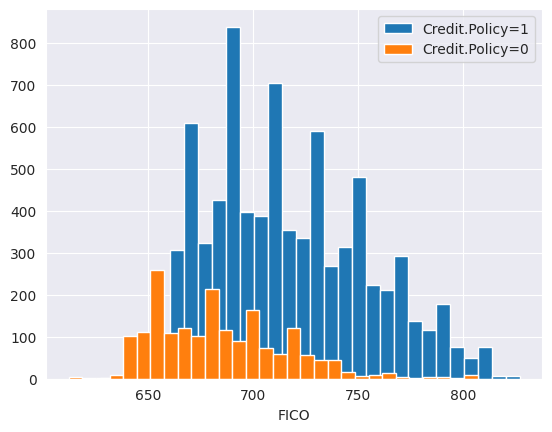

In [10]:
sns.set_style('darkgrid')
plt.hist(df['fico'].loc[df['credit.policy'] == 1],bins=30, label='Credit.Policy=1')
plt.hist(df['fico'].loc[df['credit.policy'] == 0],bins=30, label='Credit.Policy=0')
plt.legend()
plt.xlabel('FICO')


Text(0.5, 0, 'FICO')

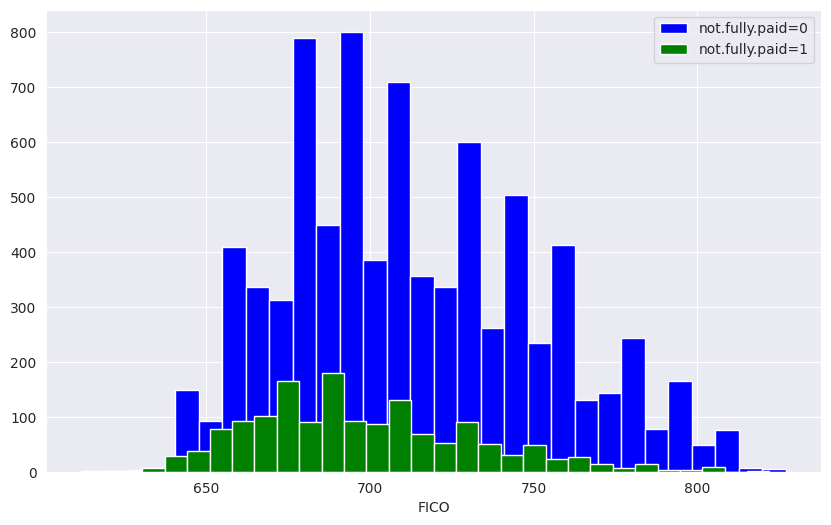

In [11]:
plt.figure(figsize=(10,6))
plt.hist(df['fico'].loc[df['not.fully.paid'] == 0],bins=30 , label='not.fully.paid=0',color='blue')
plt.hist(df['fico'].loc[df['not.fully.paid'] == 1],bins=30 , label='not.fully.paid=1',color='green')
plt.legend()
plt.xlabel('FICO')

<Axes: xlabel='purpose', ylabel='count'>

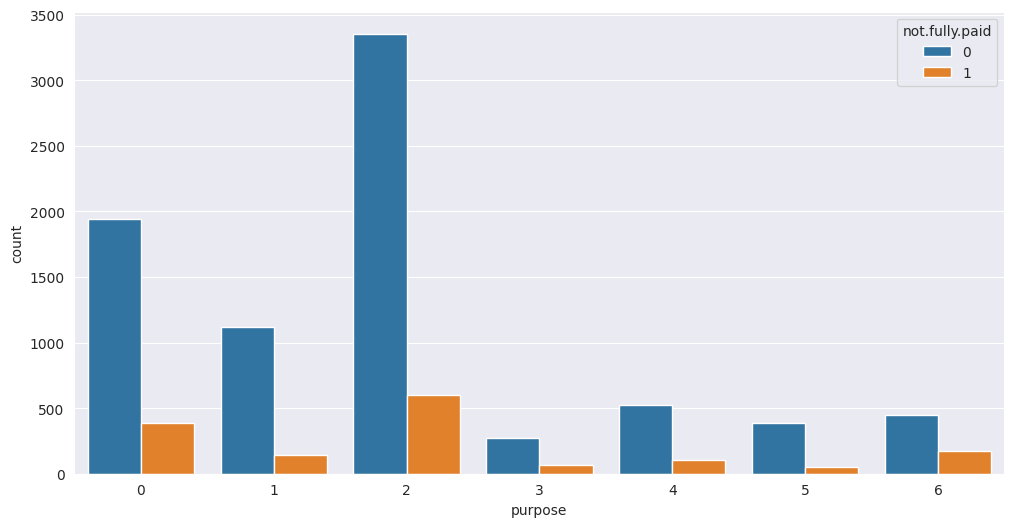

In [12]:
plt.figure(figsize=(12,6))
sns.countplot(data=df, x='purpose', hue='not.fully.paid')

<Figure size 1000x600 with 0 Axes>

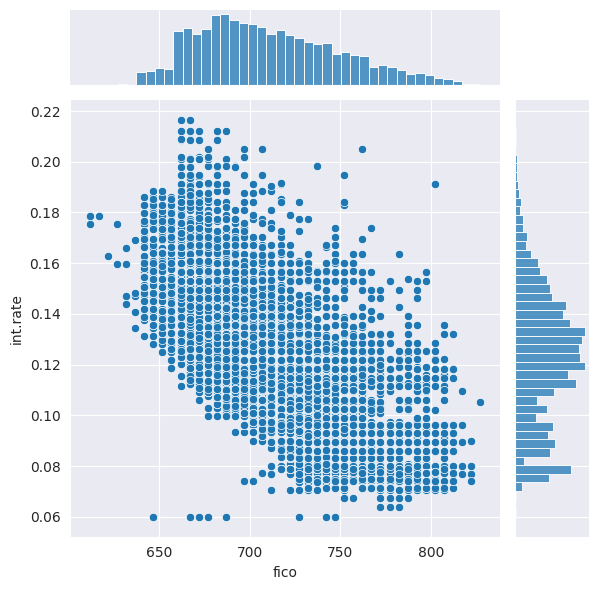

In [13]:
plt.figure(figsize=(10,6))
sns.jointplot(x='fico', y='int.rate', data=df)

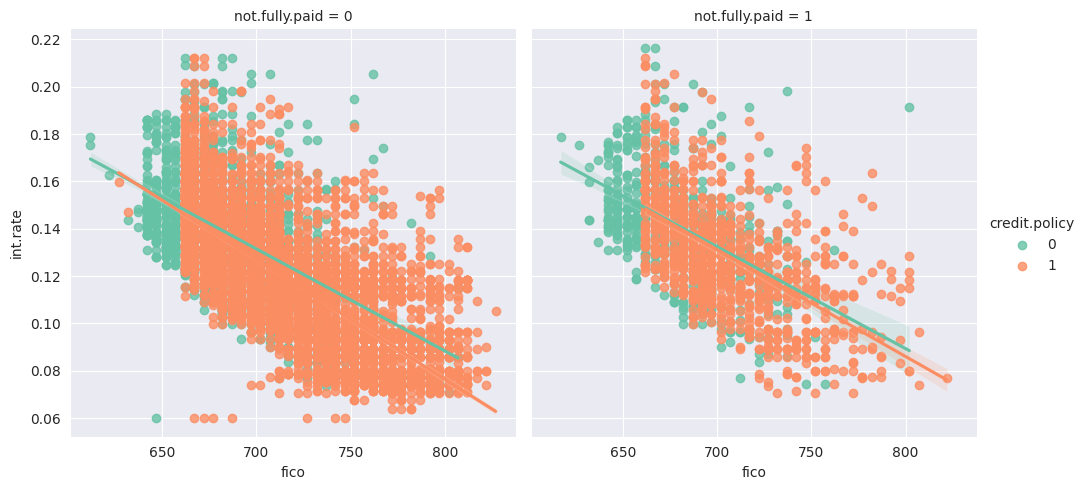

In [14]:
sns.lmplot(data=df, x='fico', y='int.rate', hue='credit.policy', col='not.fully.paid', palette='Set2')

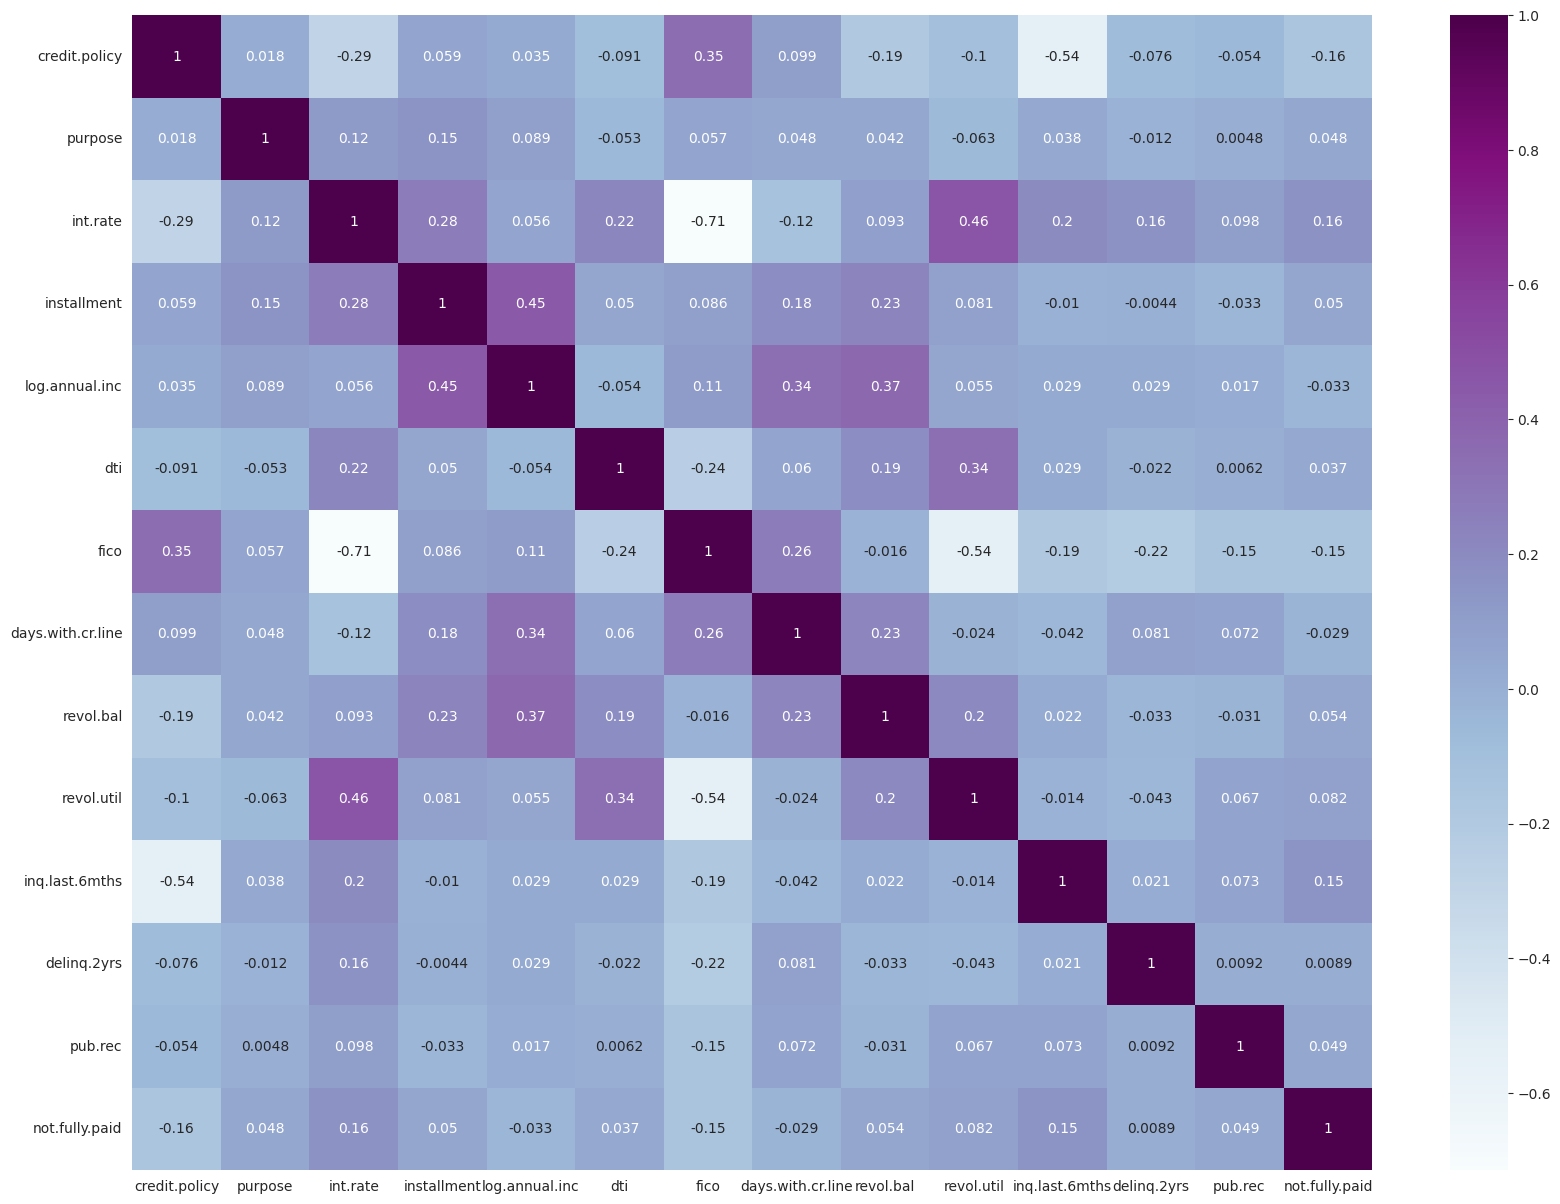

In [15]:
plt.figure(figsize = (20, 15))
sns.heatmap(df.corr(), cmap='BuPu', annot=True)
plt.show()

# **Train Test Split**

In [16]:
X = df.drop('not.fully.paid',axis = 1)
y = df['not.fully.paid']

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# **Decision Tree**

In [18]:
from sklearn.tree import DecisionTreeClassifier

dt_clf = DecisionTreeClassifier()
param_grid = {'max_depth': [2,3, 4,5,6,7,8,9,10,11,13,15,20]}

grid_search = GridSearchCV(dt_clf,param_grid,scoring = 'recall_weighted',cv=kFold, return_train_score=True)
grid_search.fit(X_train,y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=None, shuffle=False),
             estimator=DecisionTreeClassifier(),
             param_grid={'max_depth': [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13, 15,
                                       20]},
             return_train_score=True, scoring='recall_weighted')

In [19]:
grid_search.best_params_

{'max_depth': 2}

In [20]:
dt_clf = DecisionTreeClassifier(max_depth=2)
dt_clf.fit(X_train,y_train)
y_train_pred = dt_clf.predict(X_train)
y_test_pred = dt_clf.predict(X_test)

train_acc = accuracy_score(y_train,y_train_pred)
test_acc = accuracy_score(y_test,y_test_pred)

print('Train Accuracy: ',train_acc)
print('Test Accuracy: ',test_acc)

Train Accuracy:  0.8408412887828163
Test Accuracy:  0.83785664578984


In [21]:
print("Confusion Matrix \n",confusion_matrix(y_test,y_test_pred))
print("\n")
print("<-------------------Classification Report---------------------->\n")
print(classification_report(y_test,y_test_pred))
print("\n")
print("<---------------Accuracy Scores------------------->\n")
print('Train Accuracy score: ',train_acc)
print('Test Accuracy score:',test_acc)

Confusion Matrix 
 [[2408    0]
 [ 466    0]]


<-------------------Classification Report---------------------->

              precision    recall  f1-score   support

           0       0.84      1.00      0.91      2408
           1       0.00      0.00      0.00       466

    accuracy                           0.84      2874
   macro avg       0.42      0.50      0.46      2874
weighted avg       0.70      0.84      0.76      2874



<---------------Accuracy Scores------------------->

Train Accuracy score:  0.8408412887828163
Test Accuracy score: 0.83785664578984


# **Bagging for Decision Tree**

In [22]:
from sklearn.ensemble import BaggingClassifier
from sklearn.model_selection import cross_val_score
scaler=StandardScaler()
X_scaled = scaler.fit_transform(X)
bag_dt = BaggingClassifier(estimator=DecisionTreeClassifier(max_depth=2),n_estimators=100,bootstrap=True)
score = cross_val_score(estimator=bag_dt, X=X_scaled, y=y, scoring='recall_weighted', cv=kFold, n_jobs=-1)
print('Mean score:', score.mean())

Mean score: 0.7310162599410215


# **AdaBoost with Decision Tree**

In [23]:
from sklearn.ensemble import AdaBoostClassifier

adaboost_clf = AdaBoostClassifier(estimator = DecisionTreeClassifier(max_depth=2), learning_rate = 0.5)
adaboost_clf.fit(X_train, y_train)
print('Train score: {0:0.2f}'.format(adaboost_clf.score(X_train, y_train)))
print('Test score: {0:0.2f}'.format(adaboost_clf.score(X_test, y_test)))

Train score: 0.84
Test score: 0.84


# **Random Forest Classifier**

In [24]:
from sklearn.ensemble import RandomForestClassifier
rf_clf = RandomForestClassifier()
rf_clf.fit(X_train,y_train)
y_train_pred = rf_clf.predict(X_train)
y_test_pred = rf_clf.predict(X_test)

train_acc = accuracy_score(y_train,y_train_pred)
test_acc = accuracy_score(y_test,y_test_pred)

print('Train Accuracy: ',train_acc)
print('Test Accuracy: ',test_acc)

Train Accuracy:  1.0
Test Accuracy:  0.8357689631176062


In [25]:
print("Confusion Matrix \n",confusion_matrix(y_test,y_test_pred))
print("\n")
print("<-------------------Classification Report---------------------->\n")
print(classification_report(y_test,y_test_pred))
print("\n")
print("<---------------Accuracy Scores------------------->\n")
#print('Train Accuracy score: ',train_acc)
print('Test Accuracy score:',test_acc)

Confusion Matrix 
 [[2393   15]
 [ 457    9]]


<-------------------Classification Report---------------------->

              precision    recall  f1-score   support

           0       0.84      0.99      0.91      2408
           1       0.38      0.02      0.04       466

    accuracy                           0.84      2874
   macro avg       0.61      0.51      0.47      2874
weighted avg       0.76      0.84      0.77      2874



<---------------Accuracy Scores------------------->

Test Accuracy score: 0.8357689631176062


# **AdaBoosting with RandomForest**

In [26]:
from sklearn.ensemble import AdaBoostClassifier

adaboost_clf = AdaBoostClassifier(estimator = RandomForestClassifier(), learning_rate = 0.5)
adaboost_clf.fit(X_train, y_train)
print('Train score: {0:0.2f}'.format(adaboost_clf.score(X_train, y_train)))
print('Test score: {0:0.2f}'.format(adaboost_clf.score(X_test, y_test)))

y_pred_train = adaboost_clf.predict(X_train)
y_pred_test = adaboost_clf.predict(X_test)

train_accuracy = accuracy_score(y_train, y_pred_train)
test_accuracy = accuracy_score(y_test, y_pred_test)

Train score: 1.00
Test score: 0.84


In [27]:
print("Confusion Matrix \n",confusion_matrix(y_test,y_pred_test))
print("\n")
print("<-------------------Classification Report---------------------->\n")
print(classification_report(y_test,y_pred_test))
print("\n")
print("<---------------Accuracy Scores------------------->\n")
#print('Train Accuracy score: ',train_accuracy)
print('Test Accuracy score:',test_accuracy)


Confusion Matrix 
 [[2397   11]
 [ 455   11]]


<-------------------Classification Report---------------------->

              precision    recall  f1-score   support

           0       0.84      1.00      0.91      2408
           1       0.50      0.02      0.05       466

    accuracy                           0.84      2874
   macro avg       0.67      0.51      0.48      2874
weighted avg       0.79      0.84      0.77      2874



<---------------Accuracy Scores------------------->

Test Accuracy score: 0.83785664578984


# **Gradient Boosting**

In [28]:
from sklearn.ensemble import GradientBoostingClassifier
gb_clf = GradientBoostingClassifier(learning_rate = 0.05)
gb_clf.fit(X_train, y_train)
print('Train score: {0:0.2f}'.format(gb_clf.score(X_train, y_train)))
print('Test score: {0:0.2f}'.format(gb_clf.score(X_test, y_test)))
y_pred_train = gb_clf.predict(X_train)
y_pred_test = gb_clf.predict(X_test)

train_accuracy = accuracy_score(y_train, y_pred_train)
test_accuracy = accuracy_score(y_test, y_pred_test)

Train score: 0.85
Test score: 0.84


In [29]:
print("Confusion Matrix \n",confusion_matrix(y_test,y_pred_test))
print("\n")
print("<-------------------Classification Report---------------------->\n")
print(classification_report(y_test,y_pred_test))
print("\n")
print("<---------------Accuracy Scores------------------->\n")
print('Train Accuracy score: ',train_accuracy)
print('Test Accuracy score:',test_accuracy)


Confusion Matrix 
 [[2401    7]
 [ 460    6]]


<-------------------Classification Report---------------------->

              precision    recall  f1-score   support

           0       0.84      1.00      0.91      2408
           1       0.46      0.01      0.03       466

    accuracy                           0.84      2874
   macro avg       0.65      0.50      0.47      2874
weighted avg       0.78      0.84      0.77      2874



<---------------Accuracy Scores------------------->

Train Accuracy score:  0.8466587112171837
Test Accuracy score: 0.837508698677801


In [30]:
import joblib


In [31]:
joblib.dump(gb_clf, "loan_model.pkl")
print("Model saved successfully!")

Model saved successfully!


In [32]:
joblib.dump(LabelEncoder(), 'purpose_encoder.pkl')
print("Label encoder saved successfully!")

Label encoder saved successfully!


In [36]:
from google.colab import files
files.download("loan_model.pkl")
files.download("purpose_encoder.pkl")
files.download("loan_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>